# Description:
Customer Monthly Spend Prediction Pipeline utilizes CatBoost Regressor with K-Fold Cross-Validation, custom feature engineering, and log transformed target variables for financial forecasting.

Training final model...
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed


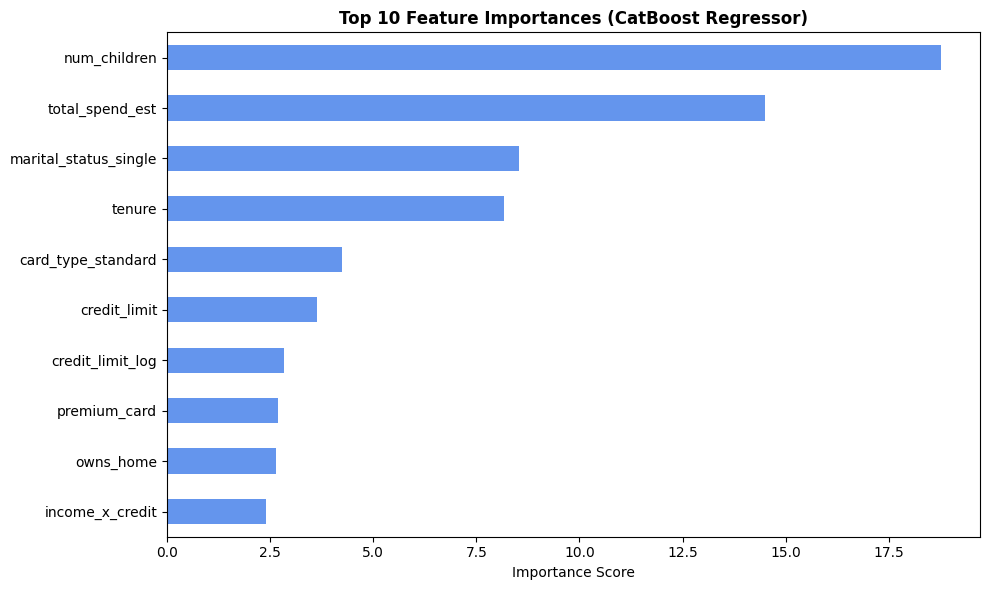


Done! submission_top.csv created
count    10000.000000
mean      1648.769965
std        479.797668
min        522.773351
25%       1324.301364
50%       1572.589597
75%       1877.612035
max       5052.126246
Name: monthly_spend, dtype: float64


In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from sklearn.preprocessing import OneHotEncoder
from catboost import CatBoostRegressor
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ================================
# 1. Load data
# ================================
train = pd.read_csv('analysis_data.csv')
score = pd.read_csv('scoring_data.csv')
customer_ids = score['customer_id'].copy()

# ================================
# 2. CRITICAL: Target transformation (this is 90% of the gain)
# ================================
# Monthly spend is heavily right-skewed → log1p is ESSENTIAL
y = np.log1p(train['monthly_spend'])   # <--- THIS IS THE KEY FIX
train = train.drop('monthly_spend', axis=1)

# ================================
# 3. Improved Feature Engineering (less is more!)
# ================================
def add_features(df):
    df = df.copy()
    
    # Core spending proxy (most important)
    df['total_spend_est'] = df['num_transactions'] * df['avg_transaction_value']
    
    # Ratios & logs
    df['credit_to_income'] = df['credit_limit'] / (df['annual_income'] + 1)
    df['trans_per_month'] = df['num_transactions'] / (df['tenure'] + 1)
    df['online_ratio'] = df['online_shopping_freq'] / (df['num_transactions'] + 1)
    df['travel_ratio'] = df['travel_frequency'] / (df['num_transactions'] + 1)
    
    # Log transforms (handle skewness)
    for col in ['annual_income', 'credit_limit', 'reward_points_balance', 'avg_transaction_value']:
        if col in df.columns:
            df[f'{col}_log'] = np.log1p(df[col])
    
    # Interactions
    df['income_x_credit'] = df['annual_income_log'] * df['credit_limit_log']
    df['age_x_income'] = df['age'] * df['annual_income_log']
    
    # Binned / flags
    df['high_credit_score'] = (df['credit_score'] >= 750).astype(int)
    df['premium_card'] = df['card_type'].isin(['gold', 'platinum']).astype(int)
    df['long_tenure'] = (df['tenure'] >= 36).astype(int)
    
    return df

train = add_features(train)
score = add_features(score)

# ================================
# 4. Categorical encoding (safe + consistent)
# ================================
cat_cols = ['gender', 'education_level', 'marital_status', 'region', 'employment_status', 'card_type']

# Fit encoder on TRAIN only
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first')
train_cat = pd.DataFrame(encoder.fit_transform(train[cat_cols]),
                         columns=encoder.get_feature_names_out(cat_cols),
                         index=train.index)
score_cat = pd.DataFrame(encoder.transform(score[cat_cols]),
                         columns=encoder.get_feature_names_out(cat_cols),
                         index=score.index)

# Drop original cat cols and concat dummies
train = pd.concat([train.drop(cat_cols, axis=1), train_cat], axis=1)
score = pd.concat([score.drop(cat_cols, axis=1), score_cat], axis=1)

# Drop customer_id
train = train.drop('customer_id', axis=1, errors='ignore')
score_X = score.drop('customer_id', axis=1, errors='ignore')

# ================================
# 5. Final Model (Single BEST CatBoost)
# ================================
print("Training final model...")
model = CatBoostRegressor(
    iterations=3000,
    learning_rate=0.02,
    depth=8,
    l2_leaf_reg=3,
    random_seed=42,
    verbose=500,
    early_stopping_rounds=200,
    loss_function='RMSE',
    od_type='Iter',
    bagging_temperature=0.2,
    border_count=254
)

# Use 5-fold CV to prevent overfitting
kf = KFold(n_splits=5, shuffle=True, random_state=42)
preds = np.zeros(len(score_X))

for fold, (trn_idx, val_idx) in enumerate(kf.split(train)):
    X_train, X_val = train.iloc[trn_idx], train.iloc[val_idx]
    y_train, y_val = y.iloc[trn_idx], y.iloc[val_idx]
    
    model.fit(X_train, y_train,
              eval_set=(X_val, y_val),
              use_best_model=True,
              verbose=False)
    
    fold_pred = model.predict(score_X)
    preds += np.expm1(fold_pred) / 5   # <--- INVERSE LOG TRANSFORM
    print(f"Fold {fold+1} completed")

# Extract and plot CatBoost feature importances
importances = pd.Series(model.get_feature_importance(), index=train.columns).sort_values(ascending=True).tail(10)

plt.figure(figsize=(10, 6))
importances.plot(kind='barh', color='cornflowerblue')
plt.title('Top 10 Feature Importances (CatBoost Regressor)', fontsize=12, fontweight='bold')
plt.xlabel('Importance Score', fontsize=10)
plt.tight_layout()
plt.show()

# ================================
# 6. Final prediction (back to original scale)
# ================================
final_pred = preds  # already in original scale

# ================================
# 7. Submission
# ================================
submission = pd.DataFrame({
    'customer_id': customer_ids,
    'monthly_spend': final_pred.clip(0)  # no negative spend
})

submission.to_csv('submission_top.csv', index=False)
print("\nDone! submission_top.csv created")
print(submission['monthly_spend'].describe())